#**RQ 1**

In [29]:
#import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
#DATA INSPECTION
data = pd.read_csv("D:/FILE EVI/JOB HUNTING/olist-marketplace-analystics/data/raw/olist_orders_dataset.csv")
print(data.info())
print(data.duplicated().sum()) #no duplicate
print(data["order_id"].duplicated().sum()) #no duplicate


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
None


0
0


Total NULL in delay_days: 0
<class 'pandas.Series'>
Index: 6535 entries, 20 to 99432
Series name: None
Non-Null Count  Dtype  
--------------  -----  
6535 non-null   float64
dtypes: float64(1)
memory usage: 102.1 KB
count    6535.000000
mean       10.620352
std        14.643844
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
max       188.000000
dtype: float64


Text(0.5, 1.0, 'Late Orders Histogram')

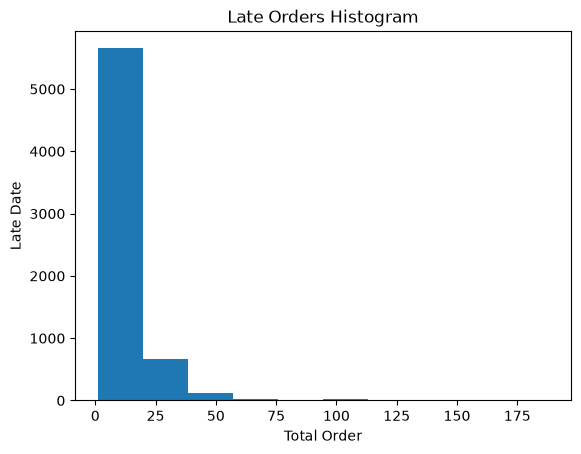

In [34]:
#DISTRIBUTION OF DELIVERY DELAYS
actual_date = pd.to_datetime(data["order_delivered_customer_date"])
estimated_date = pd.to_datetime(data["order_estimated_delivery_date"])
delay_days = (actual_date - estimated_date).dt.days
delay_days = delay_days.dropna()
print(f"Total NULL in delay_days: {delay_days.isna().sum()}")
late_orders = delay_days[delay_days>0]
late_orders.head()
late_orders.info()
#STATISTIK
print(late_orders.describe())
#HISTOGRAM
plt.hist(late_orders)
plt.xlabel("Total Order")
plt.ylabel("Late Date")
plt.title("Late Orders Histogram")




Text(0.5, 1.0, '3')

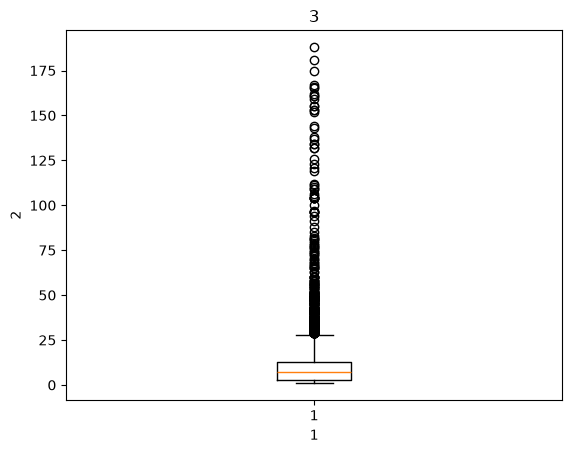

In [35]:
#BOXPLOT
plt.boxplot(late_orders)
plt.xlabel("1")
plt.ylabel("2")
plt.title("3")

In [ ]:

#upper bound = 28
outlier = (late_orders>28).sum()
total = late_orders.count()
percentage = outlier/total*100
print(f"Total Orders that is more than 28 days late: {outlier}")
print(f"Total order: {total} orders")
print(f"Percentage of outlier: {percentage.round(2)}%")

Total Orders that is more than 28 days late: 399
Total order: 6535 orders
Percentage of outlier: 6.11%


In [67]:
#MONTHLY TREND
monthly = pd.DataFrame({"purchase_date": pd.to_datetime(data.loc[delay_days.index,"order_purchase_timestamp"]), "delay_days": delay_days})
monthly["purchase_month"] = monthly["purchase_date"].dt.to_period("M")
late_orders = monthly[monthly["delay_days"]>0]
late_orders_monthly = late_orders.groupby("purchase_month").size()
total_orders_monthly = monthly.groupby("purchase_month").size()
late_rate_monthly = late_orders_monthly/total_orders_monthly*100
late_rate_monthly = late_rate_monthly.fillna(0)
#print(late_orders_monthly.head())
#print(total_orders_monthly.head())
print(late_rate_monthly)


purchase_month
2016-09    100.000000
2016-10      0.740741
2016-12      0.000000
2017-01      2.933333
2017-02      2.964307
2017-03      4.556167
2017-04      6.556665
2017-05      2.990127
2017-06      3.030303
2017-07      2.789256
2017-08      2.909611
2017-09      4.385542
2017-10      4.175971
2017-11     12.403952
2017-12      7.455106
2018-01      5.700948
2018-02     14.139719
2018-03     18.963301
2018-04      4.501324
2018-05      6.563935
2018-06      1.164698
2018-07      3.378817
2018-08      6.188002
Freq: M, dtype: float64


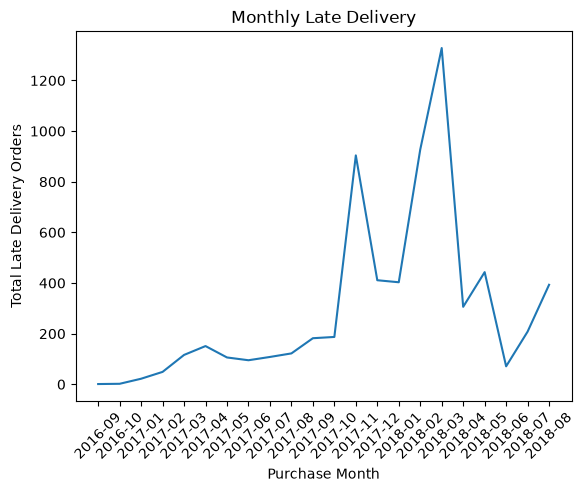

In [69]:
plt.plot(late_orders_monthly.index.astype(str), late_orders_monthly)
plt.xticks(rotation=45)
plt.xlabel("Purchase Month")
plt.ylabel("Total Late Delivery Orders")
plt.title("Monthly Late Delivery")
plt.show()

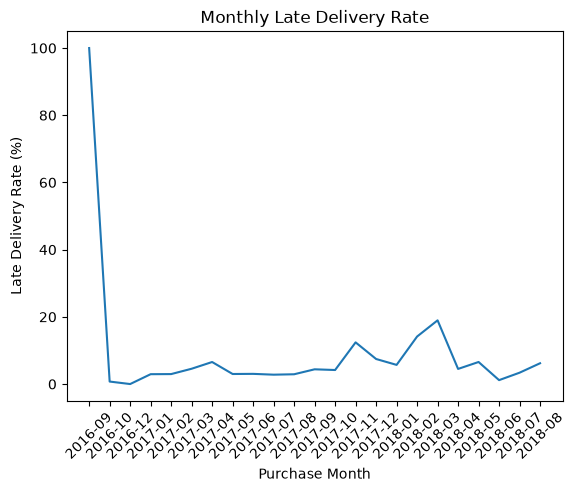

In [68]:
plt.plot(late_rate_monthly.index.astype(str), late_rate_monthly)
plt.xticks(rotation=45)
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.title("Monthly Late Delivery Rate")
plt.show()